# Defect Inspection: Exploratory Data Analysis (EDA)

This notebook performs comprehensive exploratory data analysis on the NEU-DET surface defect dataset.

### Analysis Objectives:
1. **Class and Split Distribution**: Verification of the 85/15 stratified train/val split and isolated test partition.
2. **Image Dimensions and Channels**: Verification of physical image resolutions and color channels.
3. **Bounding Box Density**: Analysis of defect instances per image.
4. **Bounding Box Geometry**: Box dimensions and aspect ratio distributions across defect categories.
5. **Visual Inspection Grid**: Visual verification of defect images with ground-truth bounding box overlays.
6. **Pixel Intensity and Contrast**: Mean and standard deviation of pixel intensities per defect category.
7. **Annotation Integrity Check**: Verification of matching image-annotation pairs and zero missing labels.
8. **Duplicate Image Analysis**: Cryptographic hash comparison to detect duplicate imagery.


In [1]:
import hashlib
from collections import Counter, defaultdict
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
from PIL import Image

CLASS_NAMES = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
CLASS_COLORS = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00", "#a65628"]
DATA_DIR = Path("../data/yolo") if Path("../data/yolo").exists() else Path("data/yolo")
FIGURES_DIR = Path("../reports/figures") if Path("../reports/figures").exists() else Path("reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


## 1. Class and Split Distribution

We verify sample counts per defect class across `train` (85%), `val` (15%), and reserved `test` splits.


Class              | Train    | Val      | Test     | Total   
----------------------------------------------------------
crazing            | 204      | 36       | 60       | 300     
inclusion          | 204      | 36       | 60       | 300     
patches            | 204      | 36       | 60       | 300     
pitted_surface     | 204      | 36       | 60       | 300     
rolled-in_scale    | 204      | 36       | 60       | 300     
scratches          | 204      | 36       | 60       | 300     


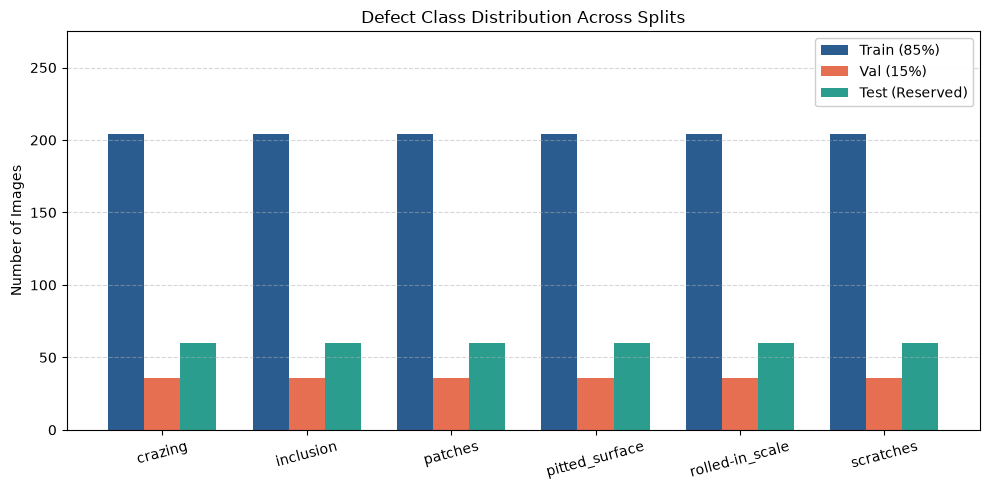

In [2]:
splits = ["train", "val", "test"]
counts_by_split = {s: {cls: 0 for cls in CLASS_NAMES} for s in splits}

for s in splits:
    for img_p in (DATA_DIR / "images" / s).glob("*.jpg"):
        for cls in CLASS_NAMES:
            if img_p.name.startswith(cls + "_"):
                counts_by_split[s][cls] += 1
                break

print(f"{'Class':<18} | {'Train':<8} | {'Val':<8} | {'Test':<8} | {'Total':<8}")
print("-" * 58)
for cls in CLASS_NAMES:
    tr = counts_by_split["train"][cls]
    vl = counts_by_split["val"][cls]
    ts = counts_by_split["test"][cls]
    print(f"{cls:<18} | {tr:<8} | {vl:<8} | {ts:<8} | {tr+vl+ts:<8}")

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(CLASS_NAMES))
width = 0.25
ax.bar(x - width, [counts_by_split["train"][c] for c in CLASS_NAMES], width, label="Train (85%)", color="#2b5c8f")
ax.bar(x, [counts_by_split["val"][c] for c in CLASS_NAMES], width, label="Val (15%)", color="#e76f51")
ax.bar(x + width, [counts_by_split["test"][c] for c in CLASS_NAMES], width, label="Test (Reserved)", color="#2a9d8f")
ax.set_ylabel("Number of Images")
ax.set_title("Defect Class Distribution Across Splits")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=15)
ax.set_ylim(0, 275)
ax.legend(loc='upper right', framealpha=0.95)
ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_class_split_distribution.png", dpi=300)
plt.show()


## 2. Image Sizes, Formats, and Color Channels

We inspect the physical image resolutions and color modes of all images in the dataset.


In [3]:
sizes = set()
modes = set()
all_images = list((DATA_DIR / "images").rglob("*.jpg"))

for img_p in all_images:
    with Image.open(img_p) as img:
        sizes.add(img.size)
        modes.add(img.mode)

print(f"Total images scanned: {len(all_images)}")
print(f"Distinct image dimensions (width, height): {sizes}")
print(f"Distinct image color modes: {modes}")


Total images scanned: 1800
Distinct image dimensions (width, height): {(200, 200)}
Distinct image color modes: {'RGB'}


## 3. Defect Instances & Bounding Boxes per Image

We analyze how many defect instances appear on a single steel strip image.


Total defect bounding boxes: 4189
Mean boxes per image: 2.33
Median boxes per image: 2.0
Range: 1 to 9 boxes per image
Frequency distribution (boxes_count: num_images): [(1, 483), (2, 673), (3, 390), (4, 154), (5, 59), (6, 22), (7, 9), (8, 6), (9, 4)]


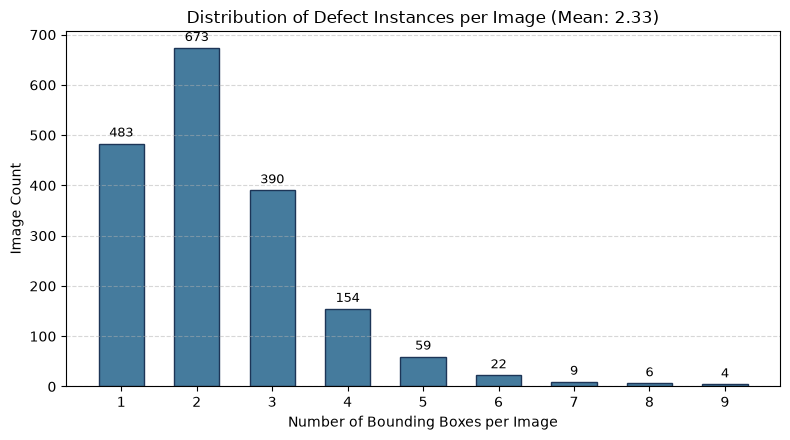

In [4]:
boxes_per_image = []
for lbl_p in (DATA_DIR / "labels").rglob("*.txt"):
    lines = [l.strip() for l in lbl_p.read_text(encoding="utf-8").splitlines() if l.strip()]
    boxes_per_image.append(len(lines))

box_counts = Counter(boxes_per_image)
print(f"Total defect bounding boxes: {sum(boxes_per_image)}")
print(f"Mean boxes per image: {np.mean(boxes_per_image):.2f}")
print(f"Median boxes per image: {np.median(boxes_per_image):.1f}")
print(f"Range: {min(boxes_per_image)} to {max(boxes_per_image)} boxes per image")
print("Frequency distribution (boxes_count: num_images):", sorted(box_counts.items()))

fig, ax = plt.subplots(figsize=(8, 4.5))
x_vals = sorted(box_counts.keys())
y_vals = [box_counts[k] for k in x_vals]
bars = ax.bar(x_vals, y_vals, color="#457b9d", edgecolor="#1d3557", width=0.6)
for bar in bars:
    h = bar.get_height()
    ax.annotate(f"{h}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3),
                textcoords="offset points", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Number of Bounding Boxes per Image")
ax.set_ylabel("Image Count")
ax.set_title(f"Distribution of Defect Instances per Image (Mean: {np.mean(boxes_per_image):.2f})")
ax.set_xticks(x_vals)
ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_boxes_per_image_distribution.png", dpi=300)
plt.show()


## 4. Bounding Box Dimensions and Aspect Ratio Distributions

We evaluate bounding box width, height, and aspect ratio ($w / h$) per defect class.


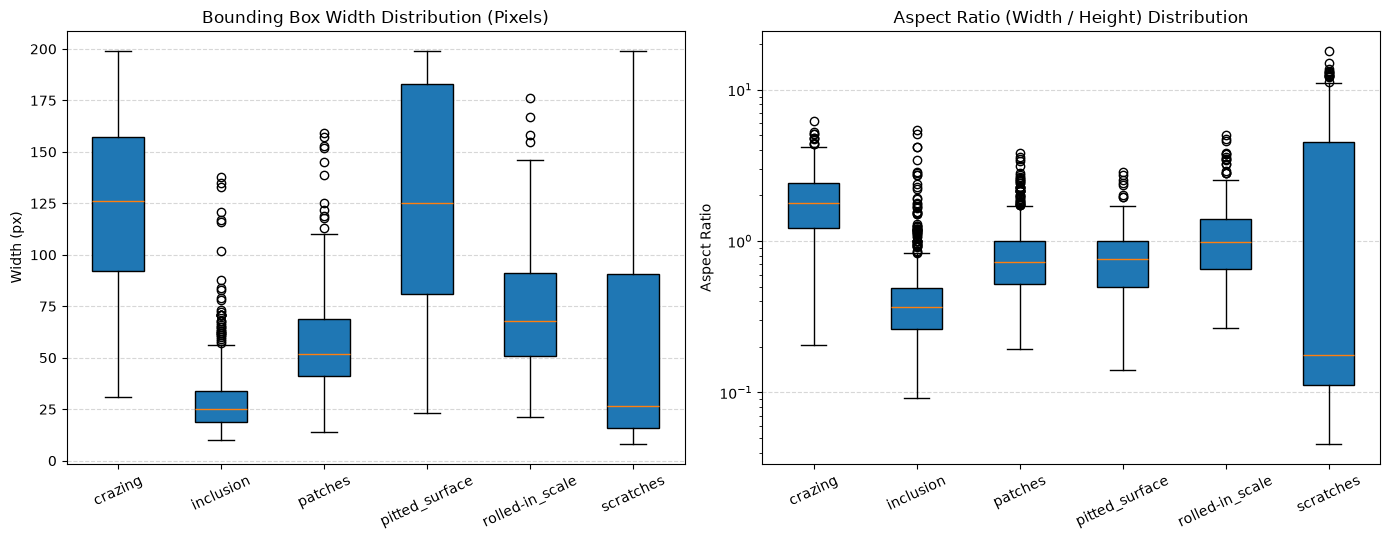

In [5]:
box_widths = {i: [] for i in range(len(CLASS_NAMES))}
box_heights = {i: [] for i in range(len(CLASS_NAMES))}
box_aspects = {i: [] for i in range(len(CLASS_NAMES))}

for lbl_p in (DATA_DIR / "labels").rglob("*.txt"):
    lines = [l.strip() for l in lbl_p.read_text(encoding="utf-8").splitlines() if l.strip()]
    for l in lines:
        cls_id, xc, yc, w, h = (float(v) for v in l.split())
        idx = int(cls_id)
        box_widths[idx].append(w * 200)
        box_heights[idx].append(h * 200)
        box_aspects[idx].append(w / max(h, 1e-5))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
ax1.boxplot([box_widths[i] for i in range(len(CLASS_NAMES))], tick_labels=CLASS_NAMES, patch_artist=True)
ax1.set_title("Bounding Box Width Distribution (Pixels)")
ax1.set_ylabel("Width (px)")
ax1.tick_params(axis="x", rotation=25)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

ax2.boxplot([box_aspects[i] for i in range(len(CLASS_NAMES))], tick_labels=CLASS_NAMES, patch_artist=True)
ax2.set_title("Aspect Ratio (Width / Height) Distribution")
ax2.set_ylabel("Aspect Ratio")
ax2.set_yscale("log")
ax2.tick_params(axis="x", rotation=25)
ax2.grid(axis="y", linestyle="--", alpha=0.5)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_box_sizes_and_aspect_ratios.png", dpi=300)
plt.show()


## 5. Visual Defect Inspection Grid with Ground Truth Bounding Boxes

We render a visual inspection gallery showing ground-truth bounding box overlays for each defect class.


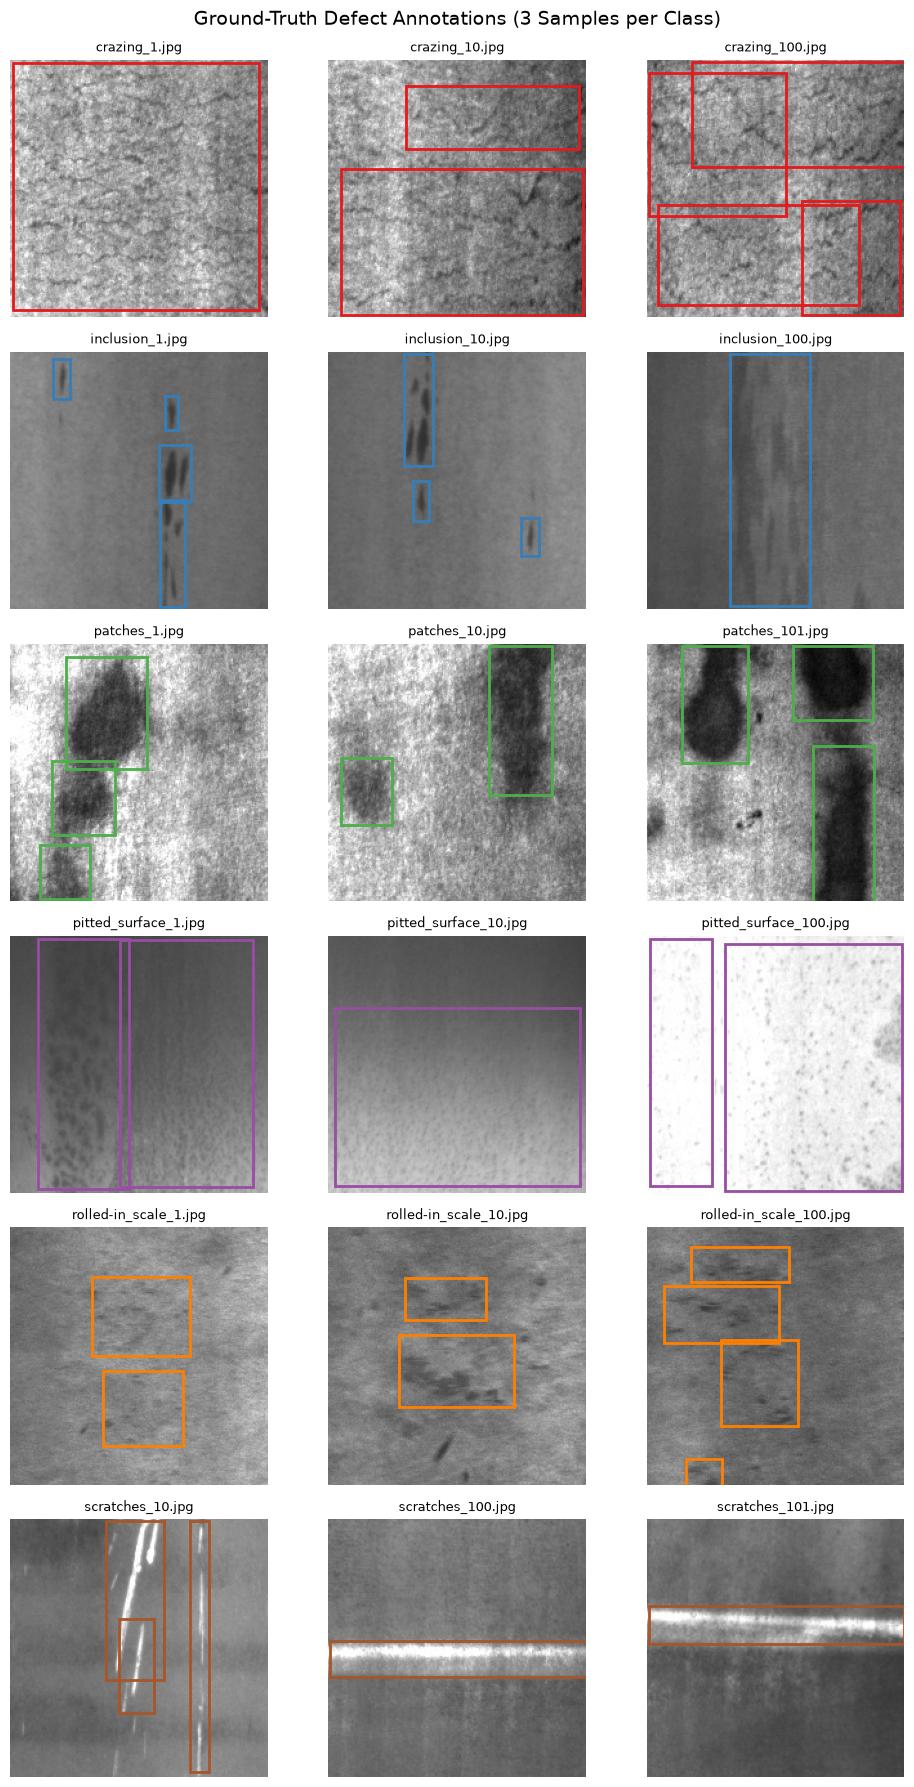

In [6]:
fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(10, 18))

for row_idx, cls_name in enumerate(CLASS_NAMES):
    samples = sorted(list((DATA_DIR / "images" / "train").glob(f"{cls_name}_*.jpg")))[:3]
    for col_idx, img_p in enumerate(samples):
        ax = axes[row_idx, col_idx]
        img = Image.open(img_p).convert("RGB")
        ax.imshow(img)
        
        lbl_p = DATA_DIR / "labels" / "train" / f"{img_p.stem}.txt"
        if lbl_p.exists():
            lines = [l.strip() for l in lbl_p.read_text(encoding="utf-8").splitlines() if l.strip()]
            for l in lines:
                cls_id, xc, yc, w, h = (float(v) for v in l.split())
                box_w = w * 200
                box_h = h * 200
                xmin = (xc * 200) - (box_w / 2.0)
                ymin = (yc * 200) - (box_h / 2.0)
                rect = patches.Rectangle((xmin, ymin), box_w, box_h, linewidth=2,
                                         edgecolor=CLASS_COLORS[int(cls_id)], facecolor="none")
                ax.add_patch(rect)
        ax.set_title(f"{img_p.name}", fontsize=9)
        ax.axis("off")

fig.suptitle("Ground-Truth Defect Annotations (3 Samples per Class)", fontsize=14, y=0.99)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_sample_defects_grid.png", dpi=300)
plt.show()


## 6. Pixel Intensity and Local Contrast Analysis

We compute the mean brightness and standard deviation (local surface contrast) for each defect category.


crazing           : Mean Intensity = 134.87 +/- 27.52, Mean Std = 28.66
inclusion         : Mean Intensity = 101.88 +/- 29.51, Mean Std = 11.89


patches           : Mean Intensity = 131.83 +/- 42.70, Mean Std = 54.16
pitted_surface    : Mean Intensity = 179.56 +/- 47.46, Mean Std = 26.77


rolled-in_scale   : Mean Intensity = 125.59 +/- 19.94, Mean Std = 16.87
scratches         : Mean Intensity = 98.12 +/- 29.45, Mean Std = 22.25


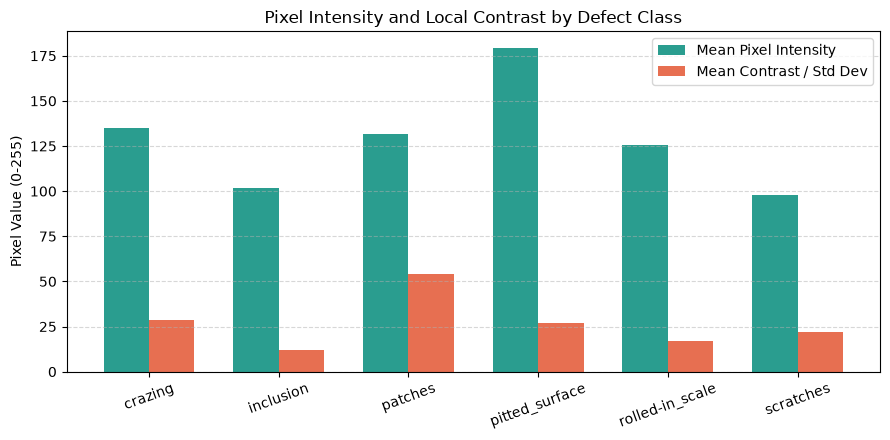

In [7]:
mean_intensities = []
std_intensities = []

for cls in CLASS_NAMES:
    cls_imgs = list((DATA_DIR / "images" / "train").glob(f"{cls}_*.jpg"))
    m_list, s_list = [], []
    for p in cls_imgs:
        arr = np.array(Image.open(p).convert("L"), dtype=np.float32)
        m_list.append(arr.mean())
        s_list.append(arr.std())
    mean_intensities.append(np.mean(m_list))
    std_intensities.append(np.mean(s_list))
    print(f"{cls:<18}: Mean Intensity = {np.mean(m_list):.2f} +/- {np.std(m_list):.2f}, Mean Std = {np.mean(s_list):.2f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(CLASS_NAMES))
width = 0.35
ax.bar(x - width/2, mean_intensities, width, label="Mean Pixel Intensity", color="#2a9d8f")
ax.bar(x + width/2, std_intensities, width, label="Mean Contrast / Std Dev", color="#e76f51")
ax.set_ylabel("Pixel Value (0-255)")
ax.set_title("Pixel Intensity and Local Contrast by Defect Class")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=20)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_pixel_intensity_distribution.png", dpi=300)
plt.show()


## 7. Annotation Integrity Check (Missing & Corrupted Labels)

We verify that every image has an associated label file, and check for missing, empty, or unparseable annotations.


In [8]:
missing_labels = []
empty_labels = []

for img_p in (DATA_DIR / "images").rglob("*.jpg"):
    rel = img_p.relative_to(DATA_DIR / "images")
    lbl_p = DATA_DIR / "labels" / rel.parent / f"{img_p.stem}.txt"
    if not lbl_p.exists():
        missing_labels.append(str(img_p))
    elif lbl_p.stat().st_size == 0:
        empty_labels.append(str(lbl_p))

print(f"Total images checked: {len(list((DATA_DIR / 'images').rglob('*.jpg')))}")
print(f"Missing label files: {len(missing_labels)}")
print(f"Empty label files: {len(empty_labels)}")
assert len(missing_labels) == 0, f"Found missing labels: {missing_labels}"
assert len(empty_labels) == 0, f"Found empty labels: {empty_labels}"


Total images checked: 1800
Missing label files: 0
Empty label files: 0


## 8. Duplicate Image Detection via Cryptographic Hashing

We compute MD5 and SHA-256 hashes of all images to detect any identical image files in the dataset.


In [9]:
hashes = defaultdict(list)
for img_p in (DATA_DIR / "images").rglob("*.jpg"):
    digest = hashlib.md5(img_p.read_bytes()).hexdigest()
    hashes[digest].append(img_p)

duplicates = {h: paths for h, paths in hashes.items() if len(paths) > 1}

print(f"Total images hashed: {len(list((DATA_DIR / 'images').rglob('*.jpg')))}")
print(f"Unique hashes: {len(hashes)}")
print(f"Identified duplicate sets: {len(duplicates)}")

for h, paths in duplicates.items():
    print(f"Hash {h}: {[p.name for p in paths]}")
    for p in paths:
        print(f"  -> Split: {p.parent.name}, Path: {p}")


Total images hashed: 1800
Unique hashes: 1799
Identified duplicate sets: 1
Hash 24f39e0f91f95e4c785052ac4d3e49a6: ['patches_101.jpg', 'patches_105.jpg']
  -> Split: train, Path: ..\data\yolo\images\train\patches_101.jpg
  -> Split: train, Path: ..\data\yolo\images\train\patches_105.jpg
